# InSAR4SM case study: Ford Dry Lake, California (Nov 2025 – Nov 2026)

**What this notebook shows:** one year of InSAR4SM surface soil moisture at the Ford Dry Lake SCAN station (Mojave Desert, California), from **NISAR (L-band)** and **Sentinel-1 (C-band)**, compared with **in-situ measurements** (ISMN, 5 cm) and with the **ERA5-Land** reanalysis that most users would otherwise use.

**Key results** (5 satellite tracks, 172 estimates, pooled):

| | RMSE vs in situ | bias | R |
|---|---|---|---|
| **InSAR4SM** (2 × 2 km mean) | **1.7 %** | −0.9 % | **0.90** |
| ERA5-Land (9 km) | 4.0 % | −3.4 % | 0.84 |

- InSAR4SM has **less than half the error of ERA5-Land** overall, and a lower error on every one of the 5 tracks.
- Combining NISAR and Sentinel-1 tracks gives an estimate on **137 days of the year: a median of 2 days between estimates**, and never more than 11.
- Maps at **125 m spacing** show the spatial pattern of wetting after rain, which a 9 km reanalysis cell cannot resolve.

This notebook reads only the small result files in `results/`, so it runs in seconds without downloading SAR data. The section *Reproduce* at the end shows how the results were produced.

In [1]:
import pandas as pd
import case_study as cs

pd.set_option('display.precision', 2)
data = cs.load_results()
h = cs.headline(data)
print('InSAR4SM: RMSE {rmse_insar:.2f} %, R {r_insar:.2f} | ERA5-Land: RMSE {rmse_era5:.2f} %, R {r_era5:.2f}'.format(**h))
print('{n_obs} estimates from {n_tracks} tracks on {n_dates} distinct days; median gap {median_gap_days:.0f} days, max gap {max_gap_days} days'.format(**h))

InSAR4SM: RMSE 1.68 %, R 0.90 | ERA5-Land: RMSE 3.95 %, R 0.84
172 estimates from 5 tracks on 137 distinct days; median gap 2 days, max gap 11 days


## 1. Site and data

| | |
|---|---|
| **Site** | Ford Dry Lake SCAN station (ISMN), 33.6547 N, −115.0976 E, Mojave Desert, California |
| **Climate / cover** | Hot desert (Köppen BWh), sparse shrubland, flat (slope 0.2°) |
| **Soil** | Sand 79 %, clay 11 % (ISMN station metadata) |
| **Area of interest** | 2 × 2 km square centred on the station (`tests/data/FordDryLake_aoi.geojson`) |
| **Period** | 2025-11-22 → 2026-11-11 (first to last NISAR acquisition) |
| **SAR** | NISAR L2 GSLC (L-band, HH) and Sentinel-1 OPERA CSLC-S1 (C-band, VV). Only the AOI window of each product is read; nothing is downloaded in full |
| **Meteorology** | ERA5-Land hourly (precipitation, skin temperature, layer-1 soil moisture) |
| **Reference** | ISMN in-situ soil moisture, 5 cm, hourly (Stevens HydraProbe) |

InSAR4SM processes every satellite track separately. The tracks over the AOI:

In [2]:
data['tracks'][['sensor', 'track', 'n_acquisitions', 'first', 'last', 'revisit_days',
                'median_consecutive_coherence', 'median_incLocal', 'valid_fraction', 'used']]

,sensor,track,n_acquisitions,first,last,revisit_days,median_consecutive_coherence,median_incLocal,valid_fraction,used
0,NISAR,005A,26,20251122,20261012,12.0,0.30,44.16,1.00,True
1,NISAR,085D,25,20251128,20261018,12.0,0.27,45.13,1.00,True
2,NISAR,106A,23,20251223,20261019,12.0,0.39,33.60,0.02,False
3,S1,100D,29,20251201,20261109,12.0,0.49,45.76,0.76,True
4,S1,166A,31,20251130,20261108,12.0,0.67,40.38,1.00,True
5,S1,173D,61,20251124,20261108,6.0,0.65,34.91,1.00,True


- `valid_fraction`: share of the AOI with SAR data on every date.
- **NISAR track 106A** is not used: its frame only touches the edge of the AOI (2 % coverage), so it has no estimate.
- **NISAR 157D** (9 acquisitions) was below the minimum of 10 acquisitions per track and was not processed.
- Sentinel-1 track 100D covers 76 % of the AOI (the AOI is at the edge of the burst).
- Sentinel-1 173D has a 6-day revisit (Sentinel-1A + 1C); the other tracks have 12 days.

## 2. One year of soil moisture

All InSAR4SM estimates (2 × 2 km mean, each point is one acquisition of one track) against the in-situ sensor and ERA5-Land. The top panel shows ERA5-Land daily precipitation.

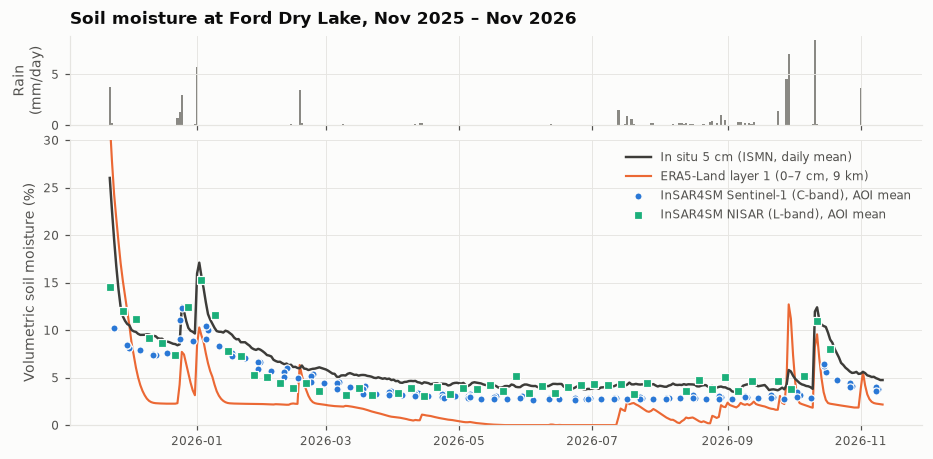

In [3]:
fig = cs.fig_overview_timeseries(data)

- **Rain events:** InSAR4SM captures the winter rain events (late Dec 2025 – early Jan 2026) and the October 2026 storm, as well as the dry-down after each of them.
- **Dry season:** it follows the 3–5 % plateau from April to September.
- **ERA5-Land:** it drops to about 0 % in early summer and overshoots some rain events, because its 9 km cell and land-surface model do not represent this desert soil well.
- **Underestimation:** InSAR4SM is slightly too low overall (bias −0.9 %), mostly in the dry season.

## 3. Accuracy per track

One panel per track: the in-situ daily mean (line), InSAR4SM (connected markers) and ERA5-Land at the same acquisition times (diamonds).

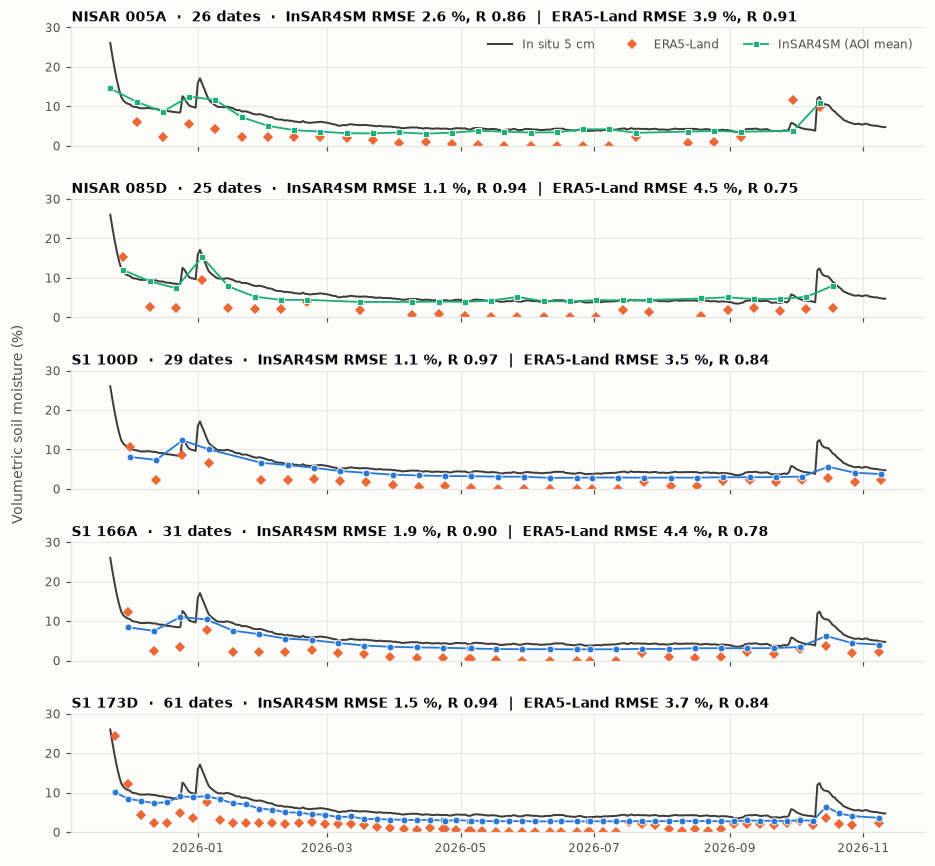

In [4]:
fig = cs.fig_tracks_timeseries(data)

In [5]:
m = cs.metrics_table(data)
m.pivot_table(index='tracks', columns='product', values=['RMSE', 'bias', 'R'], sort=False).round(2)

RMSE                                    \
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land   
tracks                                                                 
NISAR 005A                    2.56                    3.03      3.90   
NISAR 085D                    1.14                    3.51      4.53   
S1 100D                       1.06                    1.36      3.52   
S1 166A                       1.87                    2.78      4.42   
S1 173D                       1.54                    1.92      3.65   
All Sentinel-1                1.54                    2.07      3.83   
All NISAR                     1.99                    3.27      4.22   
All tracks                    1.68                    2.49      3.95   

                              bias                                    \
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land   
tracks                                                                 
NISAR 005A                   -0.62                   -1.71     -2.63   
NISAR 085D                   -0.46                   -1.97     -3.94   
S1 100D                      -0.76                   -0.93     -3.18   
S1 166A                      -1.54                   -2.34     -4.10   
S1 173D                      -1.04                   -0.99     -3.13   
All Sentinel-1               -1.10                   -1.32     -3.39   
All NISAR                    -0.54                   -1.84     -3.27   
All tracks                   -0.93                   -1.47     -3.36   

                                 R                                    
product        InSAR4SM (AOI mean) InSAR4SM (station cell) ERA5-Land  
tracks                                                                
NISAR 005A                    0.86                    0.87      0.91  
NISAR 085D                    0.94                    0.34      0.75  
S1 100D                       0.97                    0.93      0.84  
S1 166A                       0.90                    0.92      0.78  
S1 173D                       0.94                    0.82      0.84  
All Sentinel-1                0.93                    0.83      0.81  
All NISAR                     0.88                    0.74      0.86  
All tracks                    0.90                    0.79      0.84

- **InSAR4SM (AOI mean)** has a lower RMSE than ERA5-Land on **every track**, with RMSE 1.1–2.6 % (vs 3.5–4.5 %).
- **Station cell:** the single InSAR4SM cell that contains the station is noisier (pooled RMSE 2.5 %) than the 2 × 2 km mean. A point sensor and a 250 m window see different soil, so averaging several cells gives a more robust comparison.
- **Sensors:** Sentinel-1 (pooled RMSE 1.5 %, R 0.93) and NISAR (RMSE 2.0 %, R 0.88) both work with the same model settings.

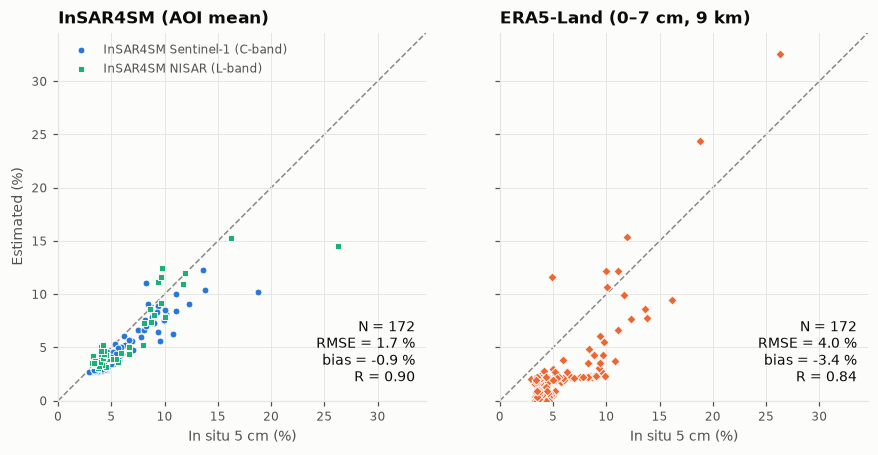

In [6]:
fig = cs.fig_scatter(data)

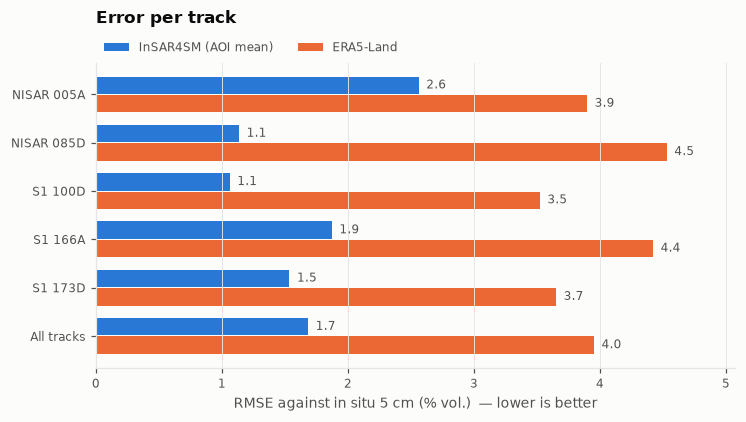

In [7]:
fig = cs.fig_rmse_bars(data)

## 4. Soil moisture maps

InSAR4SM gives a map, not just a point: here the AOI on the driest and the wettest date of the densest track (Sentinel-1 173D, 61 acquisitions). For scale, the whole 2 × 2 km AOI falls inside **one** ERA5-Land cell (about 9 × 11 km).

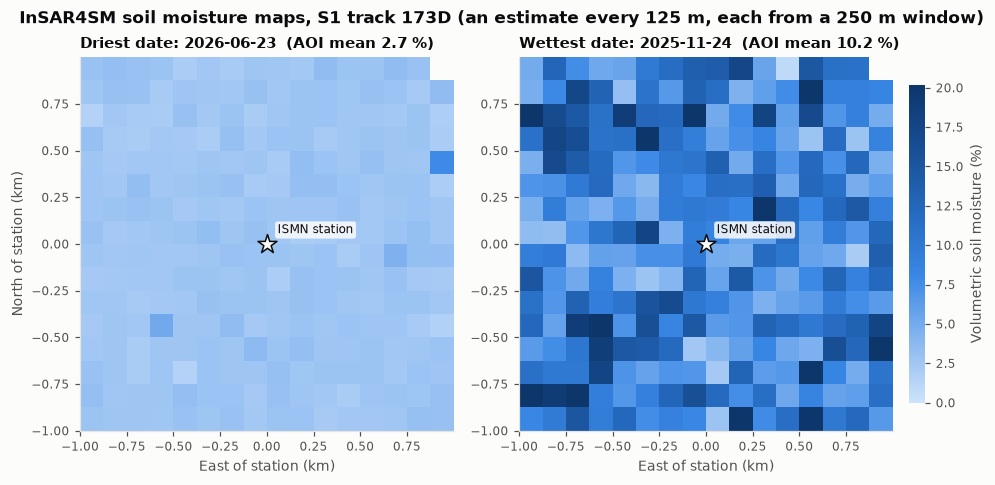

In [8]:
fig = cs.fig_maps(data)

- On the **driest date** the AOI is uniform at about 3 %.
- **After the November 2025 rain** soil moisture varies from about 3 % to 20 % between neighbouring cells. Part of that is real (micro-topography, crusts, drainage), and part is noise of the per-cell inversion.
- Use the **AOI mean or spatially averaged values** when you need the most accurate numbers, and the maps for patterns.

## 5. What this means for users

**Where InSAR4SM adds value:**
- **Accuracy:** about 2.3 times lower error than ERA5-Land at this site, from satellite data only (no in-situ calibration was used).
- **Resolution:** 125 m spacing, compared with ERA5-Land's 9 km.
- **Revisit:** combining NISAR and Sentinel-1 tracks gives an estimate every ~2 days.
- **Coverage:** worldwide. NISAR GSLC and Sentinel-1 bursts are global, and OPERA CSLC-S1 covers North America without any SAR processing on your side.

**Limitations of this case study:**
- One site, one year, and a hot desert with sparse vegetation: the setting where interferometric soil moisture works best. Vegetated or frozen areas need separate validation.
- The reference is a single 5 cm sensor. The radar senses roughly the top 1–2 cm (C-band) to about 5 cm (L-band), so some differences are expected.
- The model parameters are the defaults, tuned for C-band. L-band-specific tuning may improve the NISAR results further.
- InSAR4SM estimates are relative to the dry state of the soil. The method needs a few dry acquisitions in each stack (identified from ERA5-Land precipitation).

## 6. Reproduce

```bash
conda env create -f INSAR4SM_env.yml && conda activate insar4sm
# NASA Earthdata credentials in ~/.netrc, Copernicus CDS key in ~/.cdsapirc
python tests/smoke/run_ford_dry_lake.py --project-dir <RUN_DIR> --ismn-csv <ISMN_5cm.csv> \
    --time-start 20251122T000000 --time-end 20261111T230000 --ds --min-acquisitions 10   # ~2.5 h
python case_studies/FordDryLake/prepare_results.py --run-dir <RUN_DIR> --ismn-csv <ISMN_5cm.csv>
```

The ISMN data (station *FordDryLake*, network SCAN, 5 cm) can be downloaded from https://ismn.earth after free registration.

## References
- Karamvasis, K., & Karathanassi, V. (2023). Soil moisture estimation from Sentinel-1 interferometric observations over arid regions. *Computers & Geosciences*, 178, 105410. https://doi.org/10.1016/j.cageo.2023.105410
- Katsamas, G., Karamvasis, K., & Karathanassi, V. (2026). Toward Improved Soil Moisture Retrieval Using NISAR InSAR Closure Phase Measurements. *EARSeL Symposium, Athens*. [PDF](https://drive.google.com/file/d/1nKk2JU313nhIxNLPmR2ZAa3G-Cnvtlm3/view?usp=drive_link)

## Acknowledgements
<a href="https://github.com/moistx-labs"><img src="../../figures/moistx_logo.png" width="160" alt="moistX"></a>

The development of InSAR4SM is supported by [moistX](https://github.com/moistx-labs). The NISAR and Sentinel-1 geocoded-SLC workflow was contributed by Giorgos Katsamas ([@GiorgosKatsamas](https://github.com/GiorgosKatsamas)).

**Data credits:**
- **In situ:** International Soil Moisture Network (Dorigo et al., 2021, *Hydrol. Earth Syst. Sci.* 25, 5749–5804), network SCAN (USDA NRCS).
- **Meteorology:** ERA5-Land (Muñoz-Sabater et al., 2021), Copernicus Climate Change Service.
- **SAR:** NISAR L2 GSLC (NASA/ISRO, ASF DAAC); OPERA L2 CSLC-S1 (NASA JPL, ASF DAAC), containing modified Copernicus Sentinel data 2025–2026.